# CellVOCAL analysis of melanoma state progression

This tutorial analyzes one prepared spatial melanoma section. The ordered malignant states X0 → X1 → X3 → X4 → X5 → X6 define a weak temporal prior, while CellVOCAL learns RNA velocity and sender influence jointly from expression and spatial context.

> Start Jupyter from the repository root. Training is commented by default.

**Required files.** Place prepared inputs under `paper/data/mouse_melanoma/raw/`
and fitted H5AD files and checkpoints under `paper/data/mouse_melanoma/cellvocal/`.
The shared LR table at `paper/data/mouse_melanoma/lr_hits/lr_hits.csv` is not
bundled. To inspect saved fits without this table, comment out the
`lr_table = ...` and `lr_pairs = ...` lines in the configuration cell and keep
training commented out. The analysis cells use the fitted H5AD files and
checkpoints directly.

To train with the same common prior as the saved fits, provide that LR table.
Alternatively, configure the local CellChatDB through the public pipeline as
described in [PIPELINE.md](../../PIPELINE.md); the selected LR prior can differ
from the one used for the saved fits. These examples use the `pipeline`,
`model`, and `utils` APIs.

## Model specification

A compact ten-dimensional latent state is used with a 12-neighbor spatial graph. The malignant-state prior is smoothed once over the spatial graph so it guides temporal orientation without fixing the fitted trajectory.

In [1]:
from base64 import b64encode
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "mouse_melanoma"
SAMPLE = "Visium_melanoma_2"

lr_table = pd.read_csv(DATA_ROOT / "lr_hits" / "lr_hits.csv").fillna("")
lr_pairs = [{**row, "ligand_genes": str(row["ligand_genes"]).split(";"), "receptor_genes": str(row["receptor_genes"]).split(";")} for row in lr_table.to_dict("records")]

cfg = CellVOCALConfig()
cfg.translator.cellchatdb_dir = ROOT / "resource" / "cellchatdb"
cfg.qc.n_top_genes = 6000
cfg.qc.min_shared_counts_per_gene = 5.0
cfg.model.latent_dim = 10
cfg.model.hidden_dim = 64
cfg.model.dropout = 0.05
cfg.model.use_cell_annotation = False
cfg.model.ccc_velocity_scale = 0.1
cfg.graph.n_spatial_neighbors = 12
cfg.graph.ccc_event_budget_per_receiver = 4
cfg.train.time_prior_source = "obs"
cfg.train.time_prior_obs_key = "malignant_state_prior"
cfg.train.time_prior_smoothing_steps = 1
cfg.train.time_prior_smoothing_alpha = 0.85
cfg.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / SAMPLE / "checkpoints"
cfg.eval.output_dir = DATA_ROOT / "cellvocal" / SAMPLE / "results"

## Train CellVOCAL

The prepared H5AD already contains `obs['malignant_state_prior']` and its provenance metadata. The training stage reads that prior directly; construction and spatial imputation belong to H5AD preprocessing.

The commented call below also needs the shared `lr_pairs` table described in the availability note above.

In [3]:
# adata = ad.read_h5ad(DATA_ROOT / "raw" / f"{SAMPLE}.h5ad")
# result = run_cellvocal(adata, config=cfg, lr_pairs=lr_pairs)

## Resolve malignant-state progression

Only malignant spots are used for the state-order summary. Counts reveal class imbalance, while median fitted time and IQR show whether the learned progression follows X0 → X1 → X3 → X5 → X6. The spatial maps then show where that progression occurs.

,spots,malignant spots (%),median_time,time IQR
predicted_malignant_state,,,,
X0,818,28.344,0.369,0.238
X1,240,8.316,0.438,0.226
X3,1270,44.006,0.536,0.162
X5,481,16.667,0.660,0.173
X6,77,2.668,0.702,0.169



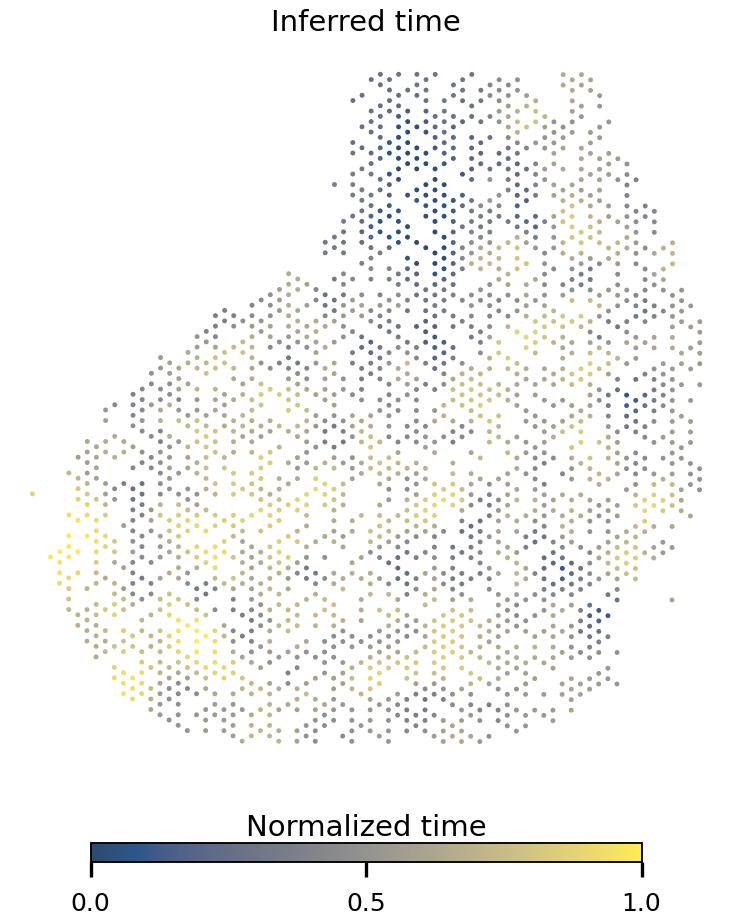
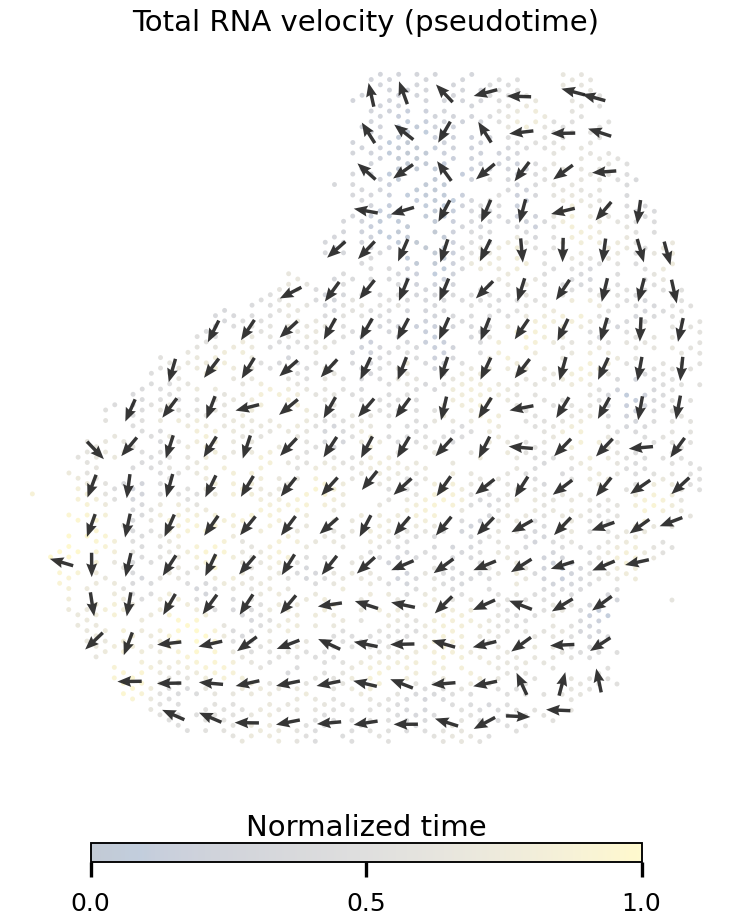

In [4]:
analysis = CellVOCALAnalysis.from_h5ad(cfg.eval.output_dir / "out.h5ad", config=cfg)
malignant = analysis.adata.obs.loc[analysis.adata.obs["cell_type"].astype(str).eq("Malignant")]
state_order = ["X0", "X1", "X3", "X5", "X6"]
state_summary = malignant.groupby("predicted_malignant_state", observed=True)["cv_time"].agg(
    spots="size", median_time="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)
).reindex(state_order)
state_summary["malignant spots (%)"] = 100 * state_summary["spots"] / state_summary["spots"].sum()
state_summary["time IQR"] = state_summary["q75"] - state_summary["q25"]
display(state_summary[["spots", "malignant spots (%)", "median_time", "time IQR"]].round(3))

with capture_output():
    velocity_plots = analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / SAMPLE / "velocity")
image_tiles = []
for path in velocity_plots:
    encoded = b64encode(Path(path).read_bytes()).decode("ascii")
    image_tiles.append(f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" style="flex:1 1 0;min-width:0;width:49%;height:auto;object-fit:contain">')
display(HTML('<div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))

## Rank communication programs

The table reports both absolute influence and share of the section-wide total, so dominant matrix/adhesion programs are distinguishable from a long tail.

In [5]:
ccc = analysis.adata.uns["cv_ccc"]
module_index = np.asarray(ccc["module"], dtype=int)
valid = (module_index >= 0) & (module_index < len(ccc["lr_pairs"]))
lr_total_influence = pd.DataFrame({"LR module": np.asarray(ccc["lr_pairs"], dtype=str)[module_index[valid]], "event_influence": np.asarray(ccc["event_influence"], dtype=float)[valid]}).query("event_influence > 0").groupby("LR module", as_index=False)["event_influence"].sum().sort_values("event_influence", ascending=False)
lr_total_influence["share (%)"] = 100 * lr_total_influence["event_influence"] / lr_total_influence["event_influence"].sum()
display(lr_total_influence.head(10).round({"event_influence": 1, "share (%)": 1}))

,LR module,event_influence,share (%)
21,Mpzl1->Mpzl1,721.4,9.1
23,Ptprm->Ptprm,482.0,6.1
14,Lama4->Itgb1,472.0,6.0
4,Cspg4->Itgb1,444.3,5.6
17,Lamb2->Itgb1,429.4,5.4
1,App->Cd74,412.2,5.2
20,Mmp2->Itgav,382.6,4.8
10,Fn1->Itgb1,374.4,4.7
13,Lama4->Itgav,373.2,4.7
16,Lamb2->Itgav,356.3,4.5


## Reuse communication analysis tools

The following examples use `pipeline.analysis.CellVOCALAnalysis`.
Calculations live in `utils/tools` and plots in `utils/viz`.
The three levels resolve a receiver's gene response, locate its
spatial sender catchment, and summarize source–section–state input
allocation. Capture spots are the observation units; input influence
and signed RNA velocity remain distinct.

In [6]:
from IPython import get_ipython
from matplotlib_inline.backend_inline import set_matplotlib_formats

get_ipython().run_line_magic("matplotlib", "inline")
set_matplotlib_formats("retina")
import matplotlib.pyplot as plt

## Define receivers and the melanocytic readout

The receiver population, signature and focal input are specified before
examining response directions. Expression and all velocity components use
the same gene-specific input SD; the original signature denominator is
retained if a gene is unavailable. The coverage table makes this explicit.
These examples use SDs from the selected section and illustrate the reusable
tools, rather than reproducing cross-section publication scaling.

In [7]:
a = analysis.adata
receiver_mask = a.obs["cell_type"].eq("Malignant")
source_labels = a.obs["cell_type"]
FOCUS = 'Mif->Cd74+Cd44'
PROGRAM_GENES = ['Mlph', 'Mitf', 'Mlana', 'Pmel', 'Slc45a2', 'Apoe', 'Dct', 'Gpnmb', 'Tyr', 'Cited1', 'Bace2', 'Cox17', 'Cox7a2', 'Ndufb2', 'Ndufb4', 'Uqcr10', 'Uqcrb']
MARKER_GENES = ['Mitf', 'Tyr', 'Dct', 'Pmel']
scale_genes = [g for g in dict.fromkeys(PROGRAM_GENES + MARKER_GENES) if g in a.var_names]
columns = a.var_names.get_indexer(scale_genes)
x = a.layers["spliced"][receiver_mask.to_numpy()][:, columns]
x = x.toarray() if hasattr(x, "toarray") else np.asarray(x)
sd = x.std(axis=0)
floor = max(float(np.median(sd[sd > 0])) * 0.01, 1e-6) if np.any(sd > 0) else 1e-6
gene_scale = pd.Series(np.maximum(sd, floor), index=scale_genes)
scores = analysis.program_scores(PROGRAM_GENES, gene_scale=gene_scale, missing="omit")
incoming = analysis.incoming_influence()
display(pd.DataFrame({"gene": PROGRAM_GENES,
                      "available": [g in a.var_names for g in PROGRAM_GENES]}))

,gene,available
0,Mlph,True
1,Mitf,True
2,Mlana,True
3,Pmel,True
4,Slc45a2,True
5,Apoe,True
6,Dct,True
7,Gpnmb,True
8,Tyr,True
9,Cited1,False


## Screen inputs associated with predicted melanocytic decline

Negative total signature velocity defines the decline readout.
High input is the upper quartile of positive influence and
background contains all other malignant spots. The plot is a
candidate screen, without a site-wise significance claim. For several
sections, concatenate aligned tables and pass `sections=` for equal
section weighting; define common gene scales before pooling.

,module,n_sections,n_valid_rho_sections,n_valid_contrast_sections,mean_rho,mean_high_delta,total_influence,n_receivers,n_observations,min_active_receivers,positive_rho_sections,positive_contrast_sections
3,Col3a1->Adgrg1,1,1,1,0.135570,0.003336,160.454680,2886,2886,405,1,1
5,Fn1->Cd44,1,1,1,0.114818,0.005272,169.588730,2886,2886,567,1,1
22,Ncam1->Ncam1,1,1,1,0.095174,0.001565,237.014928,2886,2886,884,1,1
19,Mif->Cd74+Cd44,1,1,1,0.092639,0.002220,77.433166,2886,2886,515,1,1
10,Fn1->Itgb1,1,1,1,0.070297,0.002210,303.322975,2886,2886,633,1,1
14,Lama4->Itgb1,1,1,1,0.061139,0.002340,382.675814,2886,2886,663,1,1
4,Cspg4->Itgb1,1,1,1,0.044349,0.002638,368.643858,2886,2886,661,1,1
2,App->Tyrobp,1,1,1,0.038920,0.001617,196.016862,2886,2886,609,1,1


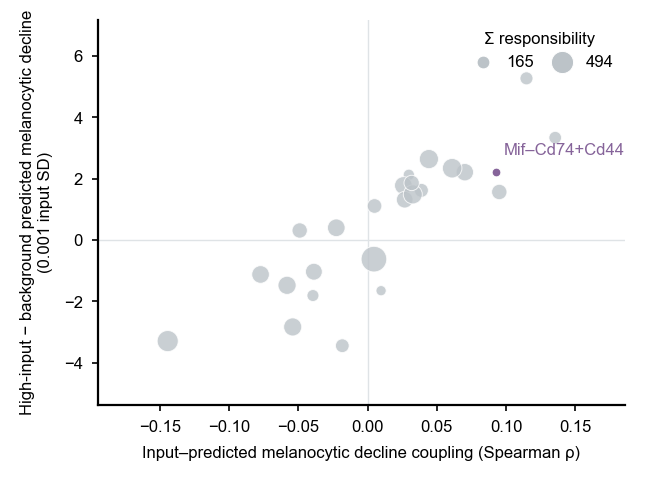

In [8]:
per_section, screening = analysis.screen_communication(
    -scores["total_velocity"], incoming=incoming,
    receiver_mask=receiver_mask, min_active=1,
    sections=np.repeat(SAMPLE, a.n_obs),
)
fig, ax = analysis.plot_communication_screen(
    screening, highlights={FOCUS: "#86649A"},
    outcome_label="Predicted melanocytic decline",
    contrast_scale=1000, outcome_units="0.001 input SD",
)
display(screening.sort_values("mean_rho", ascending=False).head(8), fig)
plt.close(fig)

## Point level: resolve one receiver's gene response

Select the receiver with greatest focal input, without using its response
sign. The checkpoint supplies the fixed response basis and mixing gate;
no training is performed. Sender contributions must reconstruct each
module response, and their sum must agree with saved communication
velocity. The ledger retains all modules, grouping those not highlighted.
Total and intrinsic velocities remain separately available in the table.

,receiver,receiver_id,gene,gene_scale,ccc_velocity_reconstructed,ccc_velocity_saved,total_velocity,intrinsic_velocity
0,270,ACCCTATAGGACTGAG-1,Mitf,2.226256,-0.025296,-0.025296,-0.022833,0.002463
1,270,ACCCTATAGGACTGAG-1,Tyr,3.963813,-0.039165,-0.039165,-0.062629,-0.023464
2,270,ACCCTATAGGACTGAG-1,Dct,16.043047,0.004942,0.004942,-0.025430,-0.030372
3,270,ACCCTATAGGACTGAG-1,Pmel,4.651796,0.004206,0.004206,0.006403,0.002197


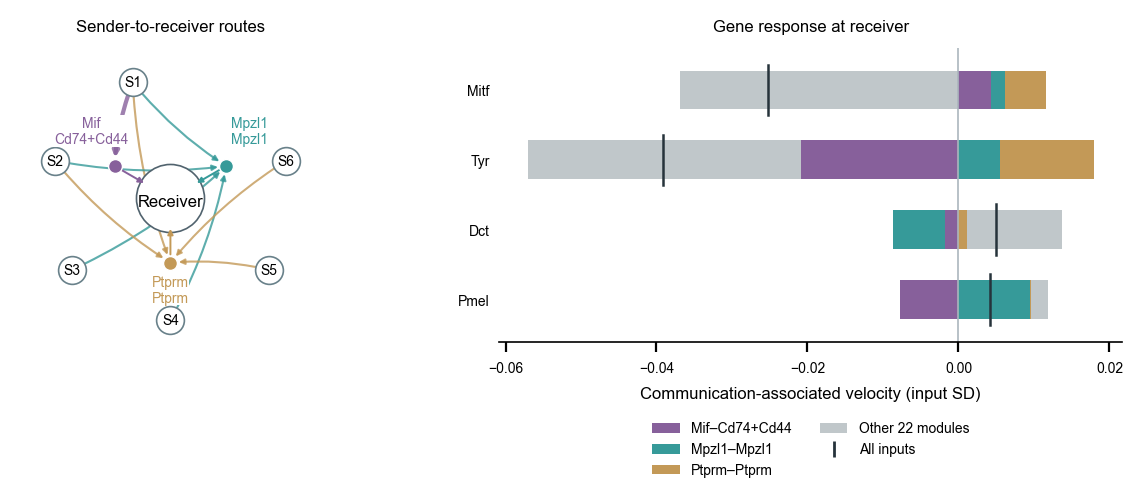

In [9]:
eligible = receiver_mask & incoming[FOCUS].gt(0)
if not eligible.any():
    raise ValueError("The selected section has no focal-input receivers.")
receiver_id = incoming.loc[eligible, FOCUS].idxmax()
receiver_index = int(a.obs_names.get_loc(receiver_id))
components = analysis.response_components()
marker_genes = [g for g in MARKER_GENES if g in a.var_names]
point = analysis.receiver_response(
    receiver_id, genes=marker_genes, gene_scale=gene_scale, components=components,
)
positive = incoming.loc[receiver_id].sort_values(ascending=False)
displayed_modules = [FOCUS] + [m for m in positive[positive > 0].index if m != FOCUS][:2]
fig, axes = analysis.plot_receiver_response(point, modules=displayed_modules)
display(point["gene_summary"], fig)
plt.close(fig)

## Tissue level: locate sender catchments and receiver dynamics

Routes remain in tissue coordinates. Receiver fill shows measured
signature expression and ring colour shows signed total velocity.
Width represents the magnitude of the attributed response across genes,
while source shares are computed from nonnegative influence.
All source classes and routes are retained in the tables. The inset is
centred on the same receiver as the point-level ledger; route selection
uses spatial position and input magnitude, never velocity sign.

,module_name,source_label,event_influence,n_events,n_senders,n_receivers,response_rms,programme_contribution,influence_fraction
0,Mif->Cd74+Cd44,Malignant,76.050120,1442,481,508,2.444195,-0.577003,0.982139
1,Mif->Cd74+Cd44,EC,0.819437,17,6,17,0.026336,-0.006217,0.010583
2,Mif->Cd74+Cd44,CAF,0.367697,10,6,9,0.011818,-0.002790,0.004749
3,Mif->Cd74+Cd44,Pericyte,0.107709,4,4,4,0.003462,-0.000817,0.001391
4,Mif->Cd74+Cd44,Monocyte.macrophage,0.088203,1,1,1,0.002835,-0.000669,0.001139


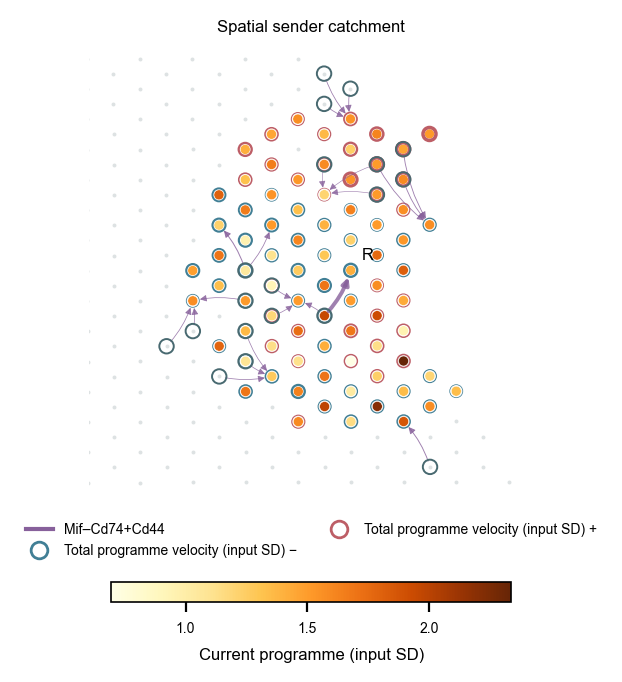

In [10]:
gene_weights = pd.Series(0.0, index=a.var_names)
available = scores.attrs["genes_available"]
gene_weights.loc[available] = 1 / (len(PROGRAM_GENES) * gene_scale.loc[available])
tissue = analysis.tissue_communication(
    modules=[FOCUS], receiver_mask=receiver_mask, source_labels=source_labels,
    observed_values=scores["current_expression"],
    velocity_values=scores["total_velocity"],
    observed_label="Current programme (input SD)",
    velocity_label="Total programme velocity (input SD)",
    gene_weights=gene_weights, **components,
)
xy = np.asarray(a.obsm["spatial"])[:, :2]
receiver_distance = np.linalg.norm(xy[receiver_mask.to_numpy()] - xy[receiver_index], axis=1)
# A comparable local view of about 80 receivers, chosen using position only.
radius = float(np.sort(receiver_distance)[min(80, len(receiver_distance) - 1)])
fig, ax = analysis.plot_sender_catchment(
    tissue, focus_receiver=receiver_index, radius=radius,
    max_receivers=10, max_routes_per_receiver=3,
)
display(tissue["source_summary"], fig)
plt.close(fig)

## Summary level: source → section → observed receiver state

MIF–CD74+CD44 input is summarized from sender classes through S2, S3 and
S4 to the current melanocytic state of malignant receivers. Link width is
input influence divided by the number of malignant spots and by
three. Sections receive equal weight, including zero-input receivers in
their denominators. The diagram conserves all selected input; it does
not show signed RNA-velocity effects.

The state score uses signature genes measured in every section, expression
rescaled to a common 10,000-total basis, and equal-section input SDs.
The original 17-gene denominator is retained and coverage is listed below.
Shared weighted tertiles define the three observed states without using
MIF input or predicted response directions.

,gene,shared_across_sections
0,Mlph,True
1,Mitf,True
2,Mlana,True
3,Pmel,True
4,Slc45a2,True
5,Apoe,True
6,Dct,True
7,Gpnmb,True
8,Tyr,True
9,Cited1,False


,section,n_receivers,section_weight,weighted_influence
0,Visium_melanoma_2,2886,0.333333,0.008944
1,Visium_melanoma_3,2381,0.333333,0.008662
2,Visium_melanoma_4,2359,0.333333,0.007411


,quantile,value,method
0,0.333333,-0.112240,weighted quantiles across all eligible receivers
1,0.666667,0.094351,weighted quantiles across all eligible receivers


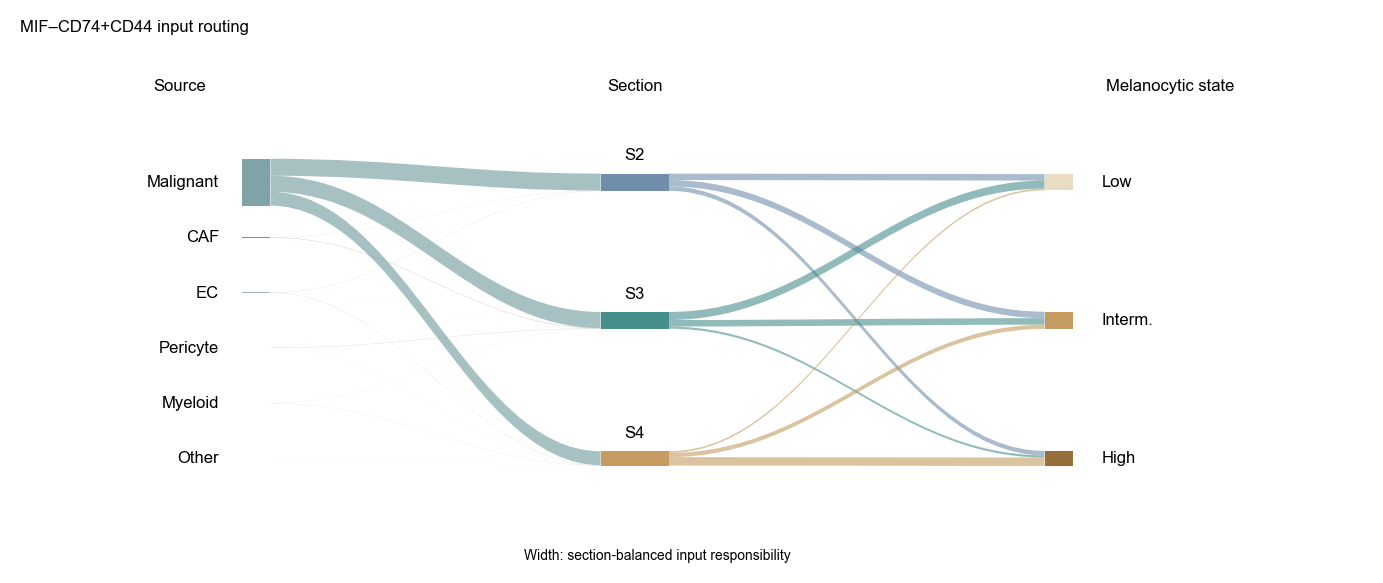

In [11]:
ROUTING_SAMPLES = ["Visium_melanoma_2", "Visium_melanoma_3", "Visium_melanoma_4"]

import h5py
from anndata.io import read_elem

routing_sections = {}
for section in ROUTING_SAMPLES:
    path = DATA_ROOT / "cellvocal" / section / "results" / "out.h5ad"
    with h5py.File(path, "r") as handle:
        obs = read_elem(handle["obs"])
        group = handle["uns/cv_ccc"]
        keys = ("sender", "receiver", "module", "lr_pairs", "event_influence",
                "module_activation_prob", "sender_share")
        routing_sections[section] = ad.AnnData(obs=obs, uns={"cv_ccc": {
            key: read_elem(group[key]) for key in keys if key in group
        }})

routing_masks = {s: value.obs["cell_type"].eq("Malignant").to_numpy()
                 for s, value in routing_sections.items()}

# Align the measured programme across sections before defining receiver states.
shared_genes = set(PROGRAM_GENES)
for section in ROUTING_SAMPLES:
    path = DATA_ROOT / "cellvocal" / section / "results" / "out.h5ad"
    with h5py.File(path, "r") as handle:
        shared_genes &= set(read_elem(handle["var"]).index)
shared_genes = [gene for gene in PROGRAM_GENES if gene in shared_genes]
if not shared_genes:
    raise ValueError("No programme genes are shared across the selected sections.")

routing_expression = {}
for section in ROUTING_SAMPLES:
    path = DATA_ROOT / "cellvocal" / section / "results" / "out.h5ad"
    with h5py.File(path, "r") as handle:
        columns = read_elem(handle["var"]).index.get_indexer(shared_genes)
        expression = read_elem(handle["layers/spliced"])[:, columns]
        expression = expression.toarray() if hasattr(expression, "toarray") else np.asarray(expression)
        target_sum = float(read_elem(handle["uns/cellvocal_qc/target_sum"]))
        routing_expression[section] = expression * (10000.0 / target_sum)

# Equal-section expression moments define common input SDs, independent of q.
means = [routing_expression[s][routing_masks[s]].mean(axis=0) for s in ROUTING_SAMPLES]
seconds = [(routing_expression[s][routing_masks[s]] ** 2).mean(axis=0) for s in ROUTING_SAMPLES]
state_mean = np.mean(means, axis=0)
state_sd = np.sqrt(np.maximum(np.mean(seconds, axis=0) - state_mean ** 2, 0))
state_floor = max(float(np.median(state_sd[state_sd > 0])) * .01, 1e-6) if np.any(state_sd > 0) else 1e-6
state_sd = np.maximum(state_sd, state_floor)
for section in ROUTING_SAMPLES:
    routing_sections[section].obs["routing_state"] = (
        (routing_expression[section] - state_mean) / state_sd
    ).sum(axis=1) / len(PROGRAM_GENES)
display(pd.DataFrame({"gene": PROGRAM_GENES,
                      "shared_across_sections": [g in shared_genes for g in PROGRAM_GENES]}))

source_groups = {name: name for name in ["Malignant", "CAF", "EC", "Pericyte", "Myeloid", "Other"]}
source_groups.update({"Monocyte.macrophage": "Myeloid", "Monocyte/macrophage": "Myeloid"})
statistics = analysis.communication_statistics(
    FOCUS, sections=routing_sections, receiver_masks=routing_masks,
    source_labels="cell_type", state_values="routing_state", weighting="section",
    source_groups=source_groups,
    source_order=["Malignant", "CAF", "EC", "Pericyte", "Myeloid", "Other"],
)
fig, ax = analysis.plot_communication_statistics(
    statistics, state_title="Melanocytic state", title="MIF–CD74+CD44 input routing",
    section_labels=dict(zip(ROUTING_SAMPLES, ["S2", "S3", "S4"])),
    state_labels={"Intermediate": "Interm."}, figsize=(6.8, 2.8),
)

display(statistics["sections"][["section", "n_receivers", "section_weight", "weighted_influence"]],
        statistics["thresholds"], fig)
plt.close(fig)
# Direct plotting data: one row per source, section, state and selected module.
# statistics["flow"].to_csv("input_routing.csv", index=False)
